In [1]:
#Installation et Imports
!pip install -q kagglehub opencv-python-headless scikit-learn tensorflow matplotlib pandas numpy

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


In [2]:
#Téléchargement du Dataset
import kagglehub

# Téléchargement automatique via kagglehub
DATA_DIR = kagglehub.dataset_download("bharathry/glaucoma-dataset-for-ai-diagnosis")
print("Chemin du dataset :", DATA_DIR)

# Inspection de l'arborescence
for root, dirs, fnames in os.walk(DATA_DIR):
    n_images = sum(1 for f in fnames if f.lower().endswith((".png", ".jpg", ".jpeg")))
    if n_images > 0:
        print(f"{root} -> {n_images} images")

Using Colab cache for faster access to the 'glaucoma-dataset-for-ai-diagnosis' dataset.
Chemin du dataset : /kaggle/input/glaucoma-dataset-for-ai-diagnosis
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/val/glaucoma/Images -> 40 images
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/val/glaucoma/Glaucoma_Positive -> 34 images
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/val/normal/Glaucoma_Negative -> 96 images
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/test/glaucoma/Images -> 400 images
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/train/glaucoma/Images - G1020 -> 1020 images
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/train/glaucoma/Images - ORIGA -> 650 images
/kaggle/input/glaucoma-dataset-for-ai-diagnosis/Glaucoma Dataset for AI Diagnosis/train/glaucoma/Images - REF

In [3]:
#Construction et Exploration du DataFrame
def build_dataframe(data_dir):
    records = []
    for root, dirs, fnames in os.walk(data_dir):
        for f in fnames:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                full_path = os.path.join(root, f)
                path_parts = [p.lower() for p in full_path.split(os.sep)]

                if "glaucoma" in path_parts:
                    label = 1
                elif "normal" in path_parts:
                    label = 0
                else:
                    continue

                records.append({"path": full_path, "label": label})
    return pd.DataFrame(records)

df = build_dataframe(DATA_DIR)
print("Nombre total d'images chargées :", len(df))
print(df["label"].value_counts().rename({0: "Sain (0)", 1: "Glaucome (1)"}))

Nombre total d'images chargées : 3160
label
Glaucome (1)    2678
Sain (0)         482
Name: count, dtype: int64


In [4]:
#Division des Données (Train / Val / Test)
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED
)

print(f"Train : {len(train_df)} images")
print(f"Val   : {len(val_df)} images")
print(f"Test  : {len(test_df)} images")

Train : 2212 images
Val   : 474 images
Test  : 474 images


In [5]:
#Fonctions de Prétraitement des Images
def load_raw(path):
    """Lecture + Resize minimal."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img.astype(np.float32)

def load_preprocessed(path):
    """Pipeline avec rehaussement de contraste CLAHE + Crop central."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Application de CLAHE dans l'espace colorimétrique LAB
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    img_eq = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2RGB)

    # Crop léger au centre
    h, w, _ = img_eq.shape
    crop_ratio = 0.9
    ch, cw = int(h * crop_ratio), int(w * crop_ratio)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    img_eq = img_eq[y0:y0 + ch, x0:x0 + cw]

    img_eq = cv2.resize(img_eq, (IMG_SIZE, IMG_SIZE))
    return img_eq.astype(np.float32)

def build_arrays(df_data, loader_fn):
    X, y = [], []
    for _, row in df_data.iterrows():
        X.append(loader_fn(row["path"]))
        y.append(row["label"])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)

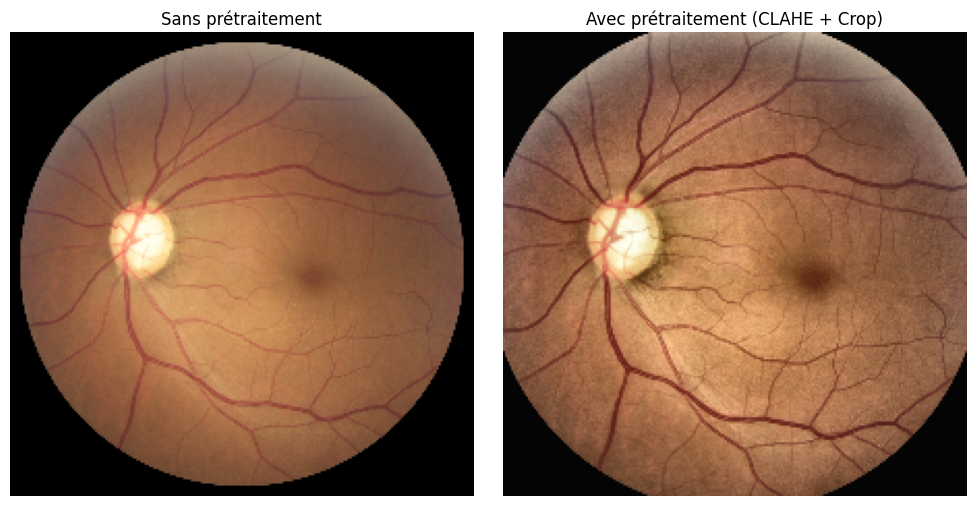

In [6]:
#Visualisation d'Exemple
sample_path = df.iloc[0]["path"]
raw_sample = load_raw(sample_path).astype(np.uint8)
prep_sample = load_preprocessed(sample_path).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(raw_sample)
axes[0].set_title("Sans prétraitement")
axes[0].axis("off")
axes[1].imshow(prep_sample)
axes[1].set_title("Avec prétraitement (CLAHE + Crop)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [7]:
#Chargement en Mémoire des Tableaux
print("Chargement pipeline SANS prétraitement...")
X_train_raw, y_train = build_arrays(train_df, load_raw)
X_val_raw, y_val = build_arrays(val_df, load_raw)
X_test_raw, y_test = build_arrays(test_df, load_raw)

print("Chargement pipeline AVEC prétraitement (CLAHE + Crop)...")
X_train_prep, _ = build_arrays(train_df, load_preprocessed)
X_val_prep, _ = build_arrays(val_df, load_preprocessed)
X_test_prep, _ = build_arrays(test_df, load_preprocessed)

print("Chargement terminé avec succès !")

Chargement pipeline SANS prétraitement...
Chargement pipeline AVEC prétraitement (CLAHE + Crop)...
Chargement terminé avec succès !


In [8]:
# Calcul des Poids de Classes
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes.tolist(), weights.tolist()))
print("Poids de classes :", class_weight_dict)

Poids de classes : {0: 3.2818991097922847, 1: 0.5898666666666667}


In [9]:
#Modèle ResNet50 et Entraînement
def build_resnet50_model(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    base = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = layers.Lambda(preprocess_input)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )
    return model

def train_model(X_tr, y_tr, X_v, y_v):
    model = build_resnet50_model()
    es = callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=5, restore_best_weights=True
    )
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_v, y_v),
        epochs=20,
        batch_size=32,
        class_weight=class_weight_dict,
        callbacks=[es],
        verbose=1,
    )
    return model, history

print("\n=== Entraînement SANS prétraitement ===")
model_raw, hist_raw = train_model(X_train_raw, y_train, X_val_raw, y_val)

print("\n=== Entraînement AVEC prétraitement ===")
model_prep, hist_prep = train_model(X_train_prep, y_train, X_val_prep, y_val)


=== Entraînement SANS prétraitement ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 41s 340ms/step - accuracy: 0.7667 - auc: 0.8562 - loss: 0.4684 - precision: 0.9527 - recall: 0.7627 - val_accuracy: 0.9325 - val_auc: 0.9737 - val_loss: 0.2246 - val_precision: 0.9973 - val_recall: 0.9229
Epoch 2/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - accuracy: 0.9010 - auc: 0.9608 - loss: 0.2366 - precision: 0.9871 - recall: 0.8949 - val_accuracy: 0.9494 - val_auc: 0.9784 - val_loss: 0.1716 - val_precision: 0.9974 - val_recall: 0.9428
Epoch 3/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 103ms/step - accuracy: 0.9304 - auc: 0.9735 - loss: 0.1836 - precision: 0.9909 - recall: 0.9264 - val_accuracy: 0.9515 - val_auc: 0.9786 - val_loss: 0.2030 - val_precision: 1.0000 - val_recall: 0.9428
Epoch 4/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.9304 - auc: 0.9726 - loss: 0.1790 - precision: 0.9948 - recall: 0.9227 - val_accuracy: 0.9515 - val_auc: 0.9797 - v

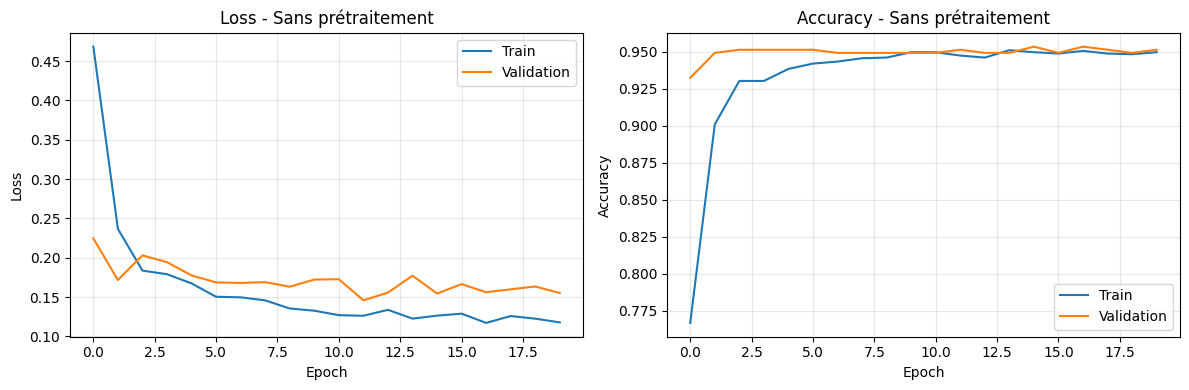

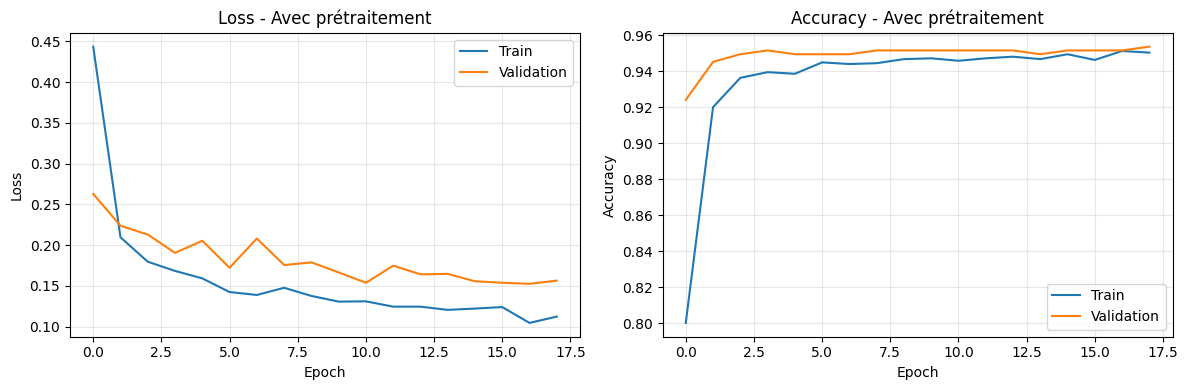

In [10]:
#Courbes d'Apprentissage
def plot_learning_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    axes[0].plot(history.history["loss"], label="Train")
    axes[0].plot(history.history["val_loss"], label="Validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(history.history["accuracy"], label="Train")
    axes[1].plot(history.history["val_accuracy"], label="Validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_learning_curves(hist_raw, "Sans prétraitement")
plot_learning_curves(hist_prep, "Avec prétraitement")

In [11]:
#Évaluation des Modèles sur l'Ensemble Test
def evaluate_model(model, X_test_data, y_test_data, name):
    y_prob = model.predict(X_test_data).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_test_data, y_pred)
    sens = recall_score(y_test_data, y_pred)
    prec = precision_score(y_test_data, y_pred)
    f1 = f1_score(y_test_data, y_pred)
    auc = roc_auc_score(y_test_data, y_prob)

    tn, fp, fn, tp = confusion_matrix(y_test_data, y_pred).ravel()
    spec = tn / (tn + fp)

    print(f"\n--- {name} ---")
    print(f"Accuracy    : {acc:.4f}")
    print(f"Sensibilité : {sens:.4f}")
    print(f"Spécificité : {spec:.4f}")
    print(f"Précision   : {prec:.4f}")
    print(f"F1-score    : {f1:.4f}")
    print(f"ROC-AUC     : {auc:.4f}")

    return {
        "name": name, "y_prob": y_prob, "y_pred": y_pred,
        "acc": acc, "sens": sens, "spec": spec, "prec": prec, "f1": f1, "auc": auc,
    }

res_raw = evaluate_model(model_raw, X_test_raw, y_test, "Sans prétraitement")
res_prep = evaluate_model(model_prep, X_test_prep, y_test, "Avec prétraitement")

15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 392ms/step

--- Sans prétraitement ---
Accuracy    : 0.9430
Sensibilité : 0.9327
Spécificité : 1.0000
Précision   : 1.0000
F1-score    : 0.9652
ROC-AUC     : 0.9820
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 368ms/step

--- Avec prétraitement ---
Accuracy    : 0.9409
Sensibilité : 0.9327
Spécificité : 0.9863
Précision   : 0.9973
F1-score    : 0.9639
ROC-AUC     : 0.9803


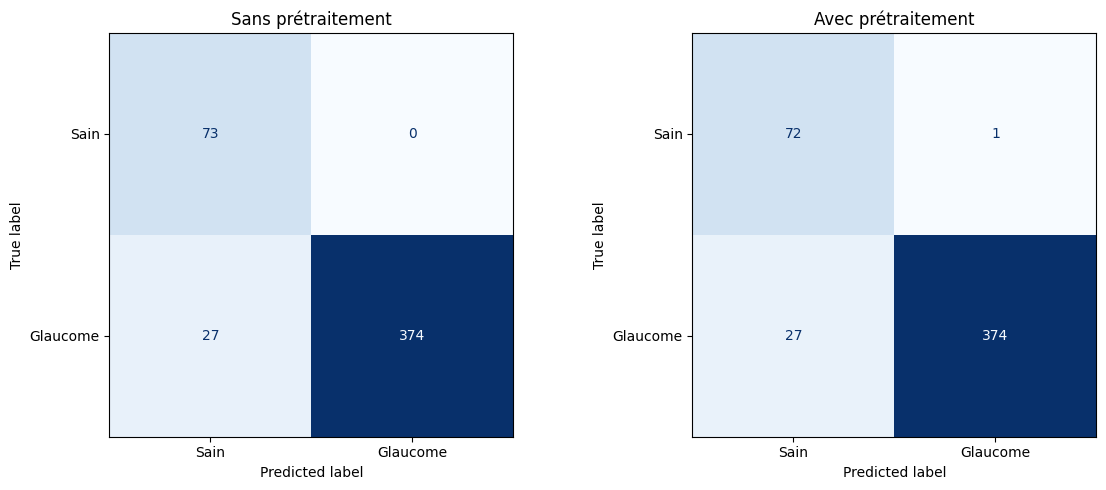

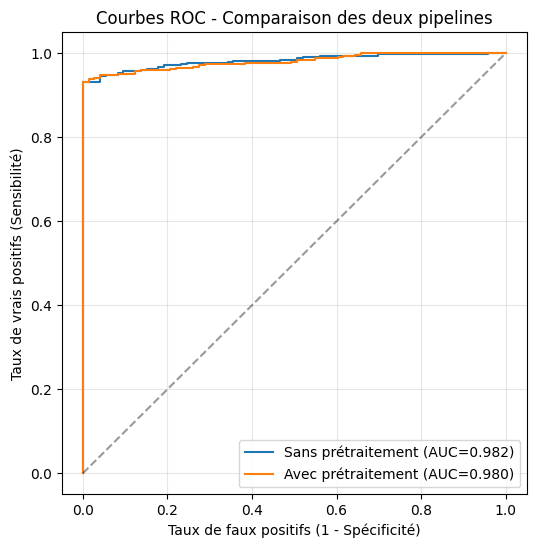

          Pipeline  Accuracy  Sensibilité  Spécificité  Précision       F1  ROC-AUC
Sans prétraitement  0.943038     0.932668     1.000000   1.000000 0.965161 0.981963
Avec prétraitement  0.940928     0.932668     0.986301   0.997333 0.963918 0.980289


In [12]:
# Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, res_raw["y_pred"]), display_labels=["Sain", "Glaucome"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Sans prétraitement")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, res_prep["y_pred"]), display_labels=["Sain", "Glaucome"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Avec prétraitement")
plt.tight_layout()
plt.show()

# Courbes ROC
fpr_raw, tpr_raw, _ = roc_curve(y_test, res_raw["y_prob"])
fpr_prep, tpr_prep, _ = roc_curve(y_test, res_prep["y_prob"])

plt.figure(figsize=(6, 6))
plt.plot(fpr_raw, tpr_raw, label=f"Sans prétraitement (AUC={res_raw['auc']:.3f})")
plt.plot(fpr_prep, tpr_prep, label=f"Avec prétraitement (AUC={res_prep['auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité)")
plt.title("Courbes ROC - Comparaison des deux pipelines")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Tableau comparatif
comparison_df = pd.DataFrame([res_raw, res_prep])[
    ["name", "acc", "sens", "spec", "prec", "f1", "auc"]
]
comparison_df.columns = [
    "Pipeline", "Accuracy", "Sensibilité", "Spécificité", "Précision", "F1", "ROC-AUC"
]
print(comparison_df.to_string(index=False))

In [ ]:
#Test sur une Nouvelle Image
from google.colab import files

print("Veuillez uploader une image de fond d'œil (fundus) :")
uploaded_image = files.upload()

if uploaded_image:
    new_image_path = list(uploaded_image.keys())[0]

    def predict_single_image(model, image_path, loader_fn, model_name):
        img = loader_fn(image_path)
        img_batch = np.expand_dims(img, axis=0)

        prob = model.predict(img_batch, verbose=0)[0][0]
        pred_label = "Glaucome" if prob >= 0.5 else "Sain"

        print(f"\n--- {model_name} ---")
        print(f"Probabilité de glaucome : {prob:.4f}")
        print(f"Prédiction : {pred_label}")
        return prob

    img_display = load_raw(new_image_path).astype(np.uint8)
    plt.figure(figsize=(5, 5))
    plt.imshow(img_display)
    plt.axis("off")
    plt.title("Image testée")
    plt.show()

    predict_single_image(model_raw, new_image_path, load_raw, "Modèle sans prétraitement")
    predict_single_image(model_prep, new_image_path, load_preprocessed, "Modèle avec prétraitement")

Veuillez uploader une image de fond d'œil (fundus) :
